# Feature engineering — Matriz de modelado (v6 → matriz)
### Tesis de Maestría · Modelo de Valuación Automática (AVM) · Rosario

Esta etapa **crea las variables predictoras** y produce la **matriz de modelado**: el dataset
*magro* que consume el modelo. A diferencia del dataset procesado (v6, ~134 columnas con toda la
trazabilidad), la matriz contiene **solo** el target, los predictores candidatos, las claves para el
*split* y las variables espaciales.

**La trazabilidad no se arrastra en columnas: la provee el pipeline.** El linaje versionado
(v1→v6 + manifiestos con hash) y las **claves** (`property_id`, `building_cluster_id`) permiten
rastrear cualquier valor con un *join* a v6. Cargar las columnas de auditoría en la matriz sería
redundante.

Todas las features son **determinísticas y por fila** (no miran a otras observaciones), así que se
crean a nivel dataset sin inducir fuga. La **imputación, el *encoding* y la selección de variables**
**no** van acá: se aprenden **por fold** en el modelado (ESL §7.10.2; Kuhn & Johnson).

### Entorno

```
pip install pandas numpy matplotlib seaborn
```

In [1]:
# ── Configuración y carga ─────────────────────────────────────────────────
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "scraping" / "zonaprop_v2"))
from features_texto import extraer_features   # regenerar feat_* desde el texto limpio

sns.set_theme(style="whitegrid", context="notebook")
PAL, PAL2, ACCENT = "#2c6e91", "#c0562b", "#3a8f5e"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5,
                     "figure.autolayout": True})

df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_eda_centro_v6.csv.gz")
print(f"v6: {len(df):,} avisos · {df.shape[1]} columnas")

v6: 4,765 avisos · 134 columnas


## 1. Texto: regenerar `feat_*` desde la descripción limpia

Los indicadores `feat_*` se recalculan sobre `descripcion_limpia` (ya saneada de HTML y de la
leyenda legal), aplicando las mismas expresiones regulares con manejo de negaciones del scraper
(`extraer_features`). Así los atributos de texto quedan libres del *boilerplate* que el EDA detectó.

19 indicadores feat_* regenerados · celdas cambiadas vs. original: 15


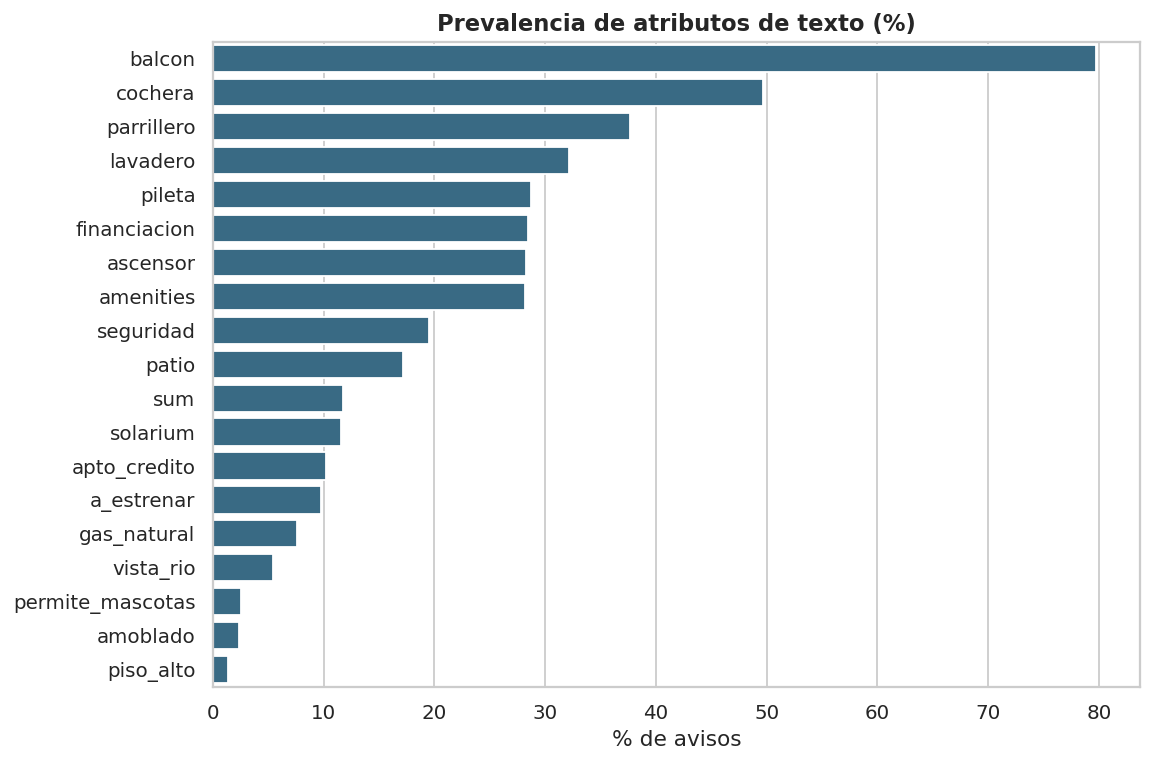

In [2]:
regen = df["descripcion_limpia"].fillna("").map(extraer_features).apply(pd.Series)
if "feat_litoral_gas" in regen.columns:
    regen = regen.rename(columns={"feat_litoral_gas": "feat_gas_natural"})
feat_cols = list(regen.columns)
comunes = [c for c in feat_cols if c in df.columns]
cambios = int(sum((df[c].fillna(0).astype(int) != regen[c].astype(int)).sum() for c in comunes))
for c in feat_cols:
    df[c] = regen[c].astype(int)
print(f"{len(feat_cols)} indicadores feat_* regenerados · celdas cambiadas vs. original: {cambios}")

prev = (df[feat_cols].mean()*100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=prev.values, y=[c.replace('feat_','') for c in prev.index], color=PAL, ax=ax)
ax.set(title="Prevalencia de atributos de texto (%)", xlabel="% de avisos", ylabel=""); plt.show()

El saneo del texto casi no altera los `feat_*` (pocos cambios), lo que sería consistente con que las
expresiones regulares ya eran específicas; pero deja los atributos derivados de un texto limpio y
reproducible, base para eventuales features de texto más ricas.

## 2. Ratios estructurales

Combinaciones de atributos físicos que suelen tener sentido hedónico. **No** usamos el precio para
construirlos (serían circulares): son relaciones entre predictores. La construcción y transformación
de predictores sigue a **Kuhn & Johnson (2019, *Feature Engineering and Selection*)** e **ISL (cap. 3)**.

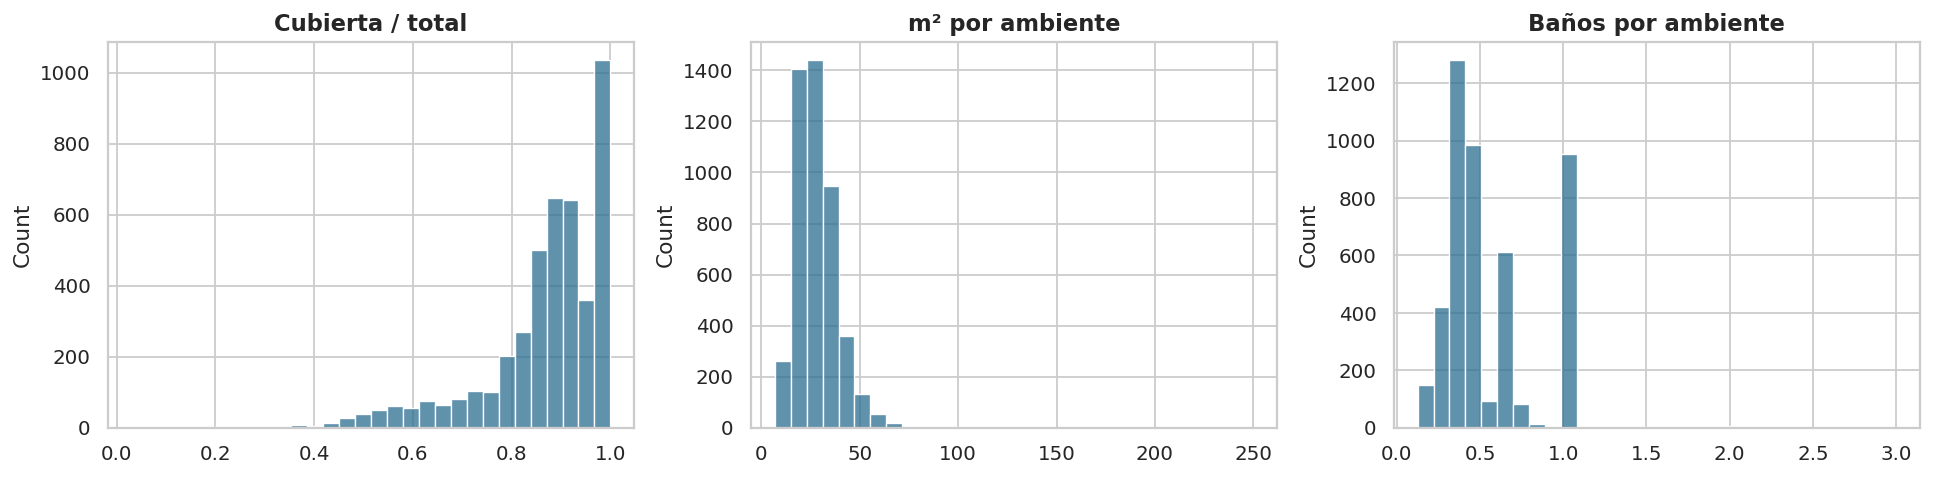

In [3]:
st = pd.to_numeric(df["eda_superficie_total_m2"], errors="coerce")
sc = pd.to_numeric(df["eda_superficie_cubierta_m2"], errors="coerce")
amb = pd.to_numeric(df["eda_ambientes"], errors="coerce").replace(0, np.nan)
df["fe_ratio_cubierta_total"] = (sc/st).where(lambda x: x <= 1.05)   # >1 es error de carga
df["fe_sup_por_ambiente"] = st/amb
df["fe_banos_por_ambiente"] = pd.to_numeric(df["eda_banos"], errors="coerce")/amb
df["fe_dormitorios_por_ambiente"] = pd.to_numeric(df["eda_dormitorios"], errors="coerce")/amb

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c, t in zip(axs, ["fe_ratio_cubierta_total","fe_sup_por_ambiente","fe_banos_por_ambiente"],
                    ["Cubierta / total","m² por ambiente","Baños por ambiente"]):
    sns.histplot(df[c].dropna(), bins=30, color=PAL, ax=ax); ax.set(title=t, xlabel="")
plt.show()

La proporción cubierta/total se concentra cerca de 0,9 (mayormente cubierta); los m² por
ambiente rondan los 26, coherente con departamentos del Centro. Son variables candidatas que el
modelo evaluará.

## 3. Indicadores de "informado" (ausencia estructural)

Para `cocheras` y `expensas`, el `NA` suele indicar **ausencia estructural** (sin cochera / no
informa expensas), no un dato perdido. En vez de imputar, creamos indicadores binarios que capturan
esa señal sin inventar valores.

In [4]:
df["fe_tiene_cochera"] = (pd.to_numeric(df["eda_cocheras"], errors="coerce").fillna(0) > 0).astype(int)
df["fe_expensas_informadas"] = df["eda_expensas"].notna().astype(int)
print("tiene_cochera:", df["fe_tiene_cochera"].value_counts().to_dict())
print("expensas_informadas:", df["fe_expensas_informadas"].value_counts().to_dict())

tiene_cochera: {0: 3529, 1: 1236}
expensas_informadas: {0: 3180, 1: 1585}


## 4. Microlocalización

Distancias determinísticas desde las coordenadas: al **centro** (Monumento a la Bandera) y al **río
Paraná** (aproximada, con un segmento de la costa frente al Centro; se refinará con la geometría del
río en la etapa espacial).

S3 externas: ['fe_dist_espacio_verde_km', 'fe_dens_comercios_300m'] 
correlación con existentes:
                           fe_dist_centro_km  fe_dist_rio_km
fe_dist_espacio_verde_km               0.14            0.18
fe_dens_comercios_300m                -0.43           -0.27


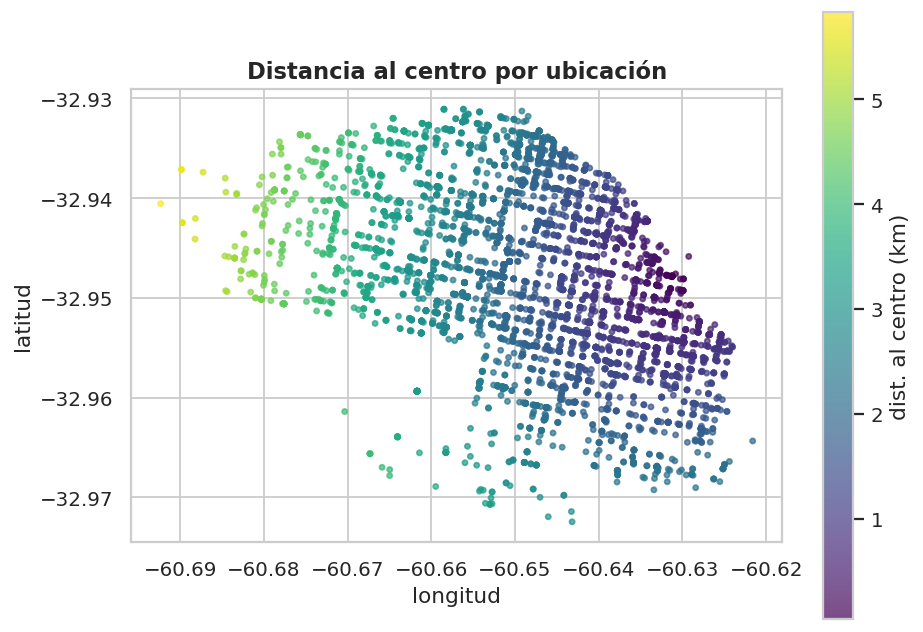

dist_centro_km: med 1.93, máx 5.83 | dist_rio_km: med 1.85, máx 5.79


In [5]:
CENTRO = (-32.9477, -60.6304)
RIO_N, RIO_S = (-32.9200, -60.6350), (-32.9750, -60.6150)

def haversine(lat, lon, lat0, lon0):
    R = 6371.0
    lat, lon, lat0, lon0 = map(np.radians, [lat, lon, lat0, lon0])
    d = np.sin((lat0-lat)/2)**2 + np.cos(lat)*np.cos(lat0)*np.sin((lon0-lon)/2)**2
    return 2*R*np.arcsin(np.sqrt(d))

def dist_a_segmento(lat, lon, a, b):
    kx = 111.320*np.cos(np.radians(lat.mean())); ky = 110.574
    px, py = (lon-a[1])*kx, (lat-a[0])*ky
    bx, by = (b[1]-a[1])*kx, (b[0]-a[0])*ky
    t = np.clip((px*bx+py*by)/(bx*bx+by*by), 0, 1)
    return np.hypot(px-t*bx, py-t*by)

lat = pd.to_numeric(df["eda_latitud"], errors="coerce"); lon = pd.to_numeric(df["eda_longitud"], errors="coerce")
df["fe_dist_centro_km"] = haversine(lat, lon, *CENTRO).round(3)
df["fe_dist_rio_km"] = dist_a_segmento(lat, lon, RIO_N, RIO_S).round(3)

# S3 externas (OSM) — solo si el POI fue descargado (scripts/feature_engineering/descargar_pois.py)
OSM = ROOT / "data" / "external" / "osm"
lat0 = float(np.nanmean(lat)); _kx = 111.320*np.cos(np.radians(lat0)); _ky = 110.574
_xy = lambda la, lo: (np.asarray(lo, float)*_kx, np.asarray(la, float)*_ky)
px, py = _xy(lat.values, lon.values); s3_ext = []
if (OSM/"espacios_verdes.csv").exists():
    g = pd.read_csv(OSM/"espacios_verdes.csv"); gx, gy = _xy(g["lat"], g["lon"])
    df["fe_dist_espacio_verde_km"] = np.array([np.min(np.hypot(gx-x, gy-y)) for x, y in zip(px, py)]).round(3)
    s3_ext.append("fe_dist_espacio_verde_km")
if (OSM/"comercios.csv").exists():
    c = pd.read_csv(OSM/"comercios.csv"); cx, cy = _xy(c["lat"], c["lon"])
    df["fe_dens_comercios_300m"] = np.array([int(np.sum(np.hypot(cx-x, cy-y) <= 0.3)) for x, y in zip(px, py)])
    s3_ext.append("fe_dens_comercios_300m")
if s3_ext:
    print("S3 externas:", s3_ext, "\ncorrelación con existentes:\n",
          df[["fe_dist_centro_km","fe_dist_rio_km"]+s3_ext].corr().loc[s3_ext,["fe_dist_centro_km","fe_dist_rio_km"]].round(2).to_string())
else:
    print("S3 externas: sin POI descargado (correr descargar_pois.py); se omiten por ahora.")

fig, ax = plt.subplots(figsize=(7.5, 7))
s = ax.scatter(lon, lat, c=df["fe_dist_centro_km"], cmap="viridis", s=8, alpha=.7)
plt.colorbar(s, ax=ax, shrink=.7, label="dist. al centro (km)")
ax.set(title="Distancia al centro por ubicación", xlabel="longitud", ylabel="latitud")
ax.set_aspect(1/np.cos(np.radians(32.95))); plt.show()
print("dist_centro_km:", f"med {df['fe_dist_centro_km'].median():.2f}, máx {df['fe_dist_centro_km'].max():.2f}",
      "| dist_rio_km:", f"med {df['fe_dist_rio_km'].median():.2f}, máx {df['fe_dist_rio_km'].max():.2f}")

El gradiente de distancia al centro es limpio y radial, como se espera. La distancia al río es
una **aproximación** útil como primera versión; en la etapa espacial se reemplazará por la distancia
a la geometría real de la costa.

## 5. Ensamblar la matriz de modelado (S1–S4)

Seleccionamos **solo** lo que consume el modelo, organizado en los escenarios **incrementales** de
información del protocolo (Gutiérrez): **S1** características estructurales, **S2** localización (S1 +
barrio y coordenadas), **S3** microlocalización y entorno (S2 + distancias a puntos de interés),
**S4** información enriquecida (S3 + texto). Son **acumulativos**: cada escenario suma sus columnas a
las del anterior, para medir el valor incremental de cada grupo de información (RQ2). Se conservan las
**claves** (para el *split group-aware* y la trazabilidad por *join*) y `geo_nivel_calidad` como
variable de **segmentación** (no predictor). El target incluye `eda_precio_usd` y su versión unitaria;
el modelado usa **uno** y no el otro como predictor.

In [6]:
target = ["eda_precio_usd", "eda_precio_m2"]
claves = ["property_id", "building_cluster_id"]
segmentacion = ["geo_nivel_calidad"]
# Escenarios incrementales (protocolo): S2 = S1+…, S3 = S2+…, S4 = S3+…
s1 = ["eda_superficie_total_m2","eda_superficie_cubierta_m2","eda_ambientes","eda_dormitorios",
      "eda_banos","eda_cocheras","eda_toilette","eda_antiguedad_anos","eda_antiguedad_estado",
      "eda_disposicion","eda_orientacion","eda_tipo_operacion","eda_expensas",
      "fe_ratio_cubierta_total","fe_sup_por_ambiente","fe_banos_por_ambiente",
      "fe_dormitorios_por_ambiente","fe_tiene_cochera","fe_expensas_informadas"]
s2 = ["barrio_oficial_geo","eda_latitud","eda_longitud"]
s3 = ["fe_dist_centro_km","fe_dist_rio_km"] + s3_ext
s4 = feat_cols
matriz = df[target+claves+segmentacion+s1+s2+s3+s4].copy()
matriz["fe_version"] = 1
resumen = pd.DataFrame({"grupo": ["target","claves","segmentación","S1 estructurales","S2 localización",
                                  "S3 microlocalización","S4 texto"],
                        "columnas": [len(target),len(claves),len(segmentacion),len(s1),len(s2),len(s3),len(s4)]})
display(resumen)
print(f"Matriz: {matriz.shape[0]:,} filas · {matriz.shape[1]} columnas  (v6 tenía {df.shape[1]})")

,grupo,columnas
0,target,2
1,claves,2
2,segmentación,1
3,S1 estructurales,19
4,S2 localización,3
5,S3 microlocalización,4
6,S4 texto,19


Matriz: 4,765 filas · 51 columnas  (v6 tenía 144)


La matriz pasa de las ~134 columnas trazables de v6 a un conjunto **magro y legible**, con cada
variable con rol explícito. Es lo que se comparte como "el dataset del modelo"; la trazabilidad
completa sigue disponible en el linaje del pipeline.

## 6. Guardar la matriz de modelado

In [7]:
salida = ROOT / "data" / "processed" / "zonaprop_v2_matriz_modelado_centro.csv.gz"
matriz.to_csv(salida, index=False, compression={"method": "gzip", "mtime": 0})
print(f"matriz escrita: {salida.relative_to(ROOT)}  ({matriz.shape[0]:,} filas · {matriz.shape[1]} columnas)")

matriz escrita: data/processed/zonaprop_v2_matriz_modelado_centro.csv.gz  (4,765 filas · 51 columnas)


## Próximos pasos (modelado)

- **Split *group-aware*** por `property_id` / `building_cluster_id` (evita fuga por republicaciones).
- **Imputación, *encoding* y selección de variables por fold** (ESL §7.10.2; Kuhn & Johnson), no a nivel dataset.
- **Escenarios S1→S4** para medir el valor incremental de cada grupo de información (Gutiérrez).
- **Spatial lag del precio (S4 supervisado, por fold):** promedio del precio de vecinos ponderado por
  distancia (KNN). Se calcula **dentro de cada fold con precios del train** —nunca como columna del
  dataset— para no filtrar información (ESL §7.10.2). Es el candidato natural de S4 y el eje de RQ4.
- Modelos: hedónico bien especificado → Random Forest → LightGBM, con diagnóstico espacial (Moran's I).

## Referencias

- Kuhn, M., & Johnson, K. (2019). *Feature Engineering and Selection: A Practical Approach for Predictive Models*. CRC Press.
- Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (cap. 3). Springer.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2ª ed.), §7.10.2. Springer.
- Gutiérrez et al. (2026) — escenarios incrementales de información (S1–S4) y republicaciones.